# Estimation and Inference: Hands-On Notebook

Practical companion to the **Estimation and Inference**      
**How to use it:** run the cells top to bottom. Every section has a *Big idea*, a small experiment, and a *What to notice* box. All data is either simulated (so we **know the truth** and can check our methods) or loaded from scikit-learn.

| Part | Concept |
|---|---|
| 1 | Estimation vs Inference (sample mean, standard error, bootstrap) |
| 2 | ML meets inference (regression coefficient + confidence interval + p-value) |
| 3 | Parametric vs Non-parametric |
| 4 | Maximum Likelihood Estimation (MLE) |
| 5 | Common distributions and where they come from |
| 6 | Frequentist vs Bayesian (the coin example) |

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
import seaborn as sns

rng = np.random.default_rng(42)          # fixed seed -> same results every run
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})
print("Setup done")

Setup done


---
## Part 1: Estimation vs Inference

> **Big idea.** *Estimation* gives you **one number** from your data. *Inference* tells you **how much to trust** that number.

### 1.1 The example 

In [35]:
data = np.array([12, 15, 11, 18, 20, 14, 16, 13])

x_bar = np.mean(data)                          # ESTIMATION
n = len(data)
se = np.std(data, ddof=1) / np.sqrt(n)         # INFERENCE (uncertainty of the estimate)

print(f"Estimate (mean): {x_bar:.2f}")
print(f"Standard error:  {se:.2f}")

Estimate (mean): 14.88
Standard error:  1.08


### 1.2 What does the standard error *mean*?

The standard error (SE) is the **standard deviation of the estimate if we repeated the study many times**. We can't repeat real studies cheaply, but with a simulated population we can.

We create a population of 100,000 people's waiting times (we *know* its true mean), then draw 5,000 different samples of size 30 and compute the mean of each.

True population mean:                   9.99
Std. dev. of 5000 sample means:         1.84   <- the 'real' uncertainty
SE computed from just ONE sample:       1.50   <- our estimate of it


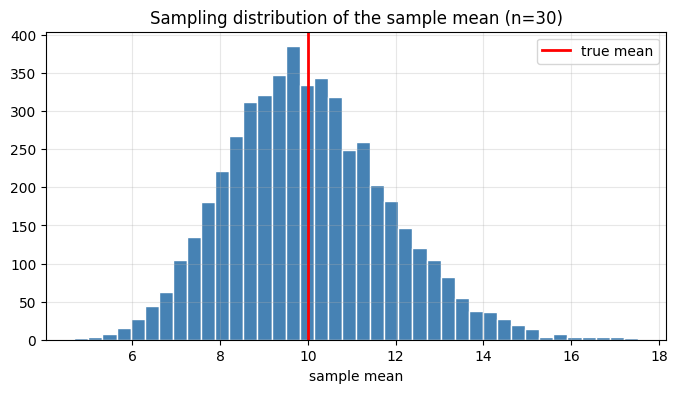

In [36]:
# A skewed "population" with a known true mean
population = rng.exponential(scale=10, size=100_000)
true_mean = population.mean()
n = 30

sample_means = np.array([rng.choice(population, size=n).mean() for _ in range(5000)])

# SE from ONE sample (what we can do in real life)
one_sample = rng.choice(population, size=n)
se_formula = one_sample.std(ddof=1) / np.sqrt(n)

print(f"True population mean:                   {true_mean:.2f}")
print(f"Std. dev. of 5000 sample means:         {sample_means.std():.2f}   <- the 'real' uncertainty")
print(f"SE computed from just ONE sample:       {se_formula:.2f}   <- our estimate of it")

plt.hist(sample_means, bins=40, color="steelblue", edgecolor="white")
plt.axvline(true_mean, color="red", lw=2, label="true mean")
plt.title("Sampling distribution of the sample mean (n=30)")
plt.xlabel("sample mean"); plt.legend(); plt.show()

> **What to notice**
> - Each sample gives a *different* mean. That spread **is** the uncertainty.
> - The histogram is centered on the true mean (the sample mean is an *unbiased* estimator).
> - One sample's formula `s/√n` closely predicts the spread you would see from thousands of repeats. That is the magic of inference.

### 1.3 More data → less uncertainty

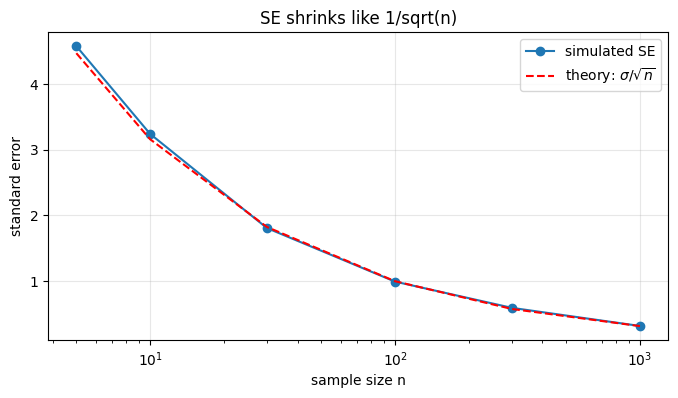

In [37]:
sizes = [5, 10, 30, 100, 300, 1000]
ses = []
for n in sizes:
    means = [rng.choice(population, size=n).mean() for _ in range(2000)]
    ses.append(np.std(means))

plt.plot(sizes, ses, "o-", label="simulated SE")
plt.plot(sizes, population.std() / np.sqrt(sizes), "r--", label=r"theory: $\sigma/\sqrt{n}$")
plt.xscale("log"); plt.xlabel("sample size n"); plt.ylabel("standard error")
plt.title("SE shrinks like 1/sqrt(n)"); plt.legend(); plt.show()

> **What to notice:** to cut your uncertainty in half you need **4× the data**, not 2×.

### 1.4 Bonus: the bootstrap, inference without a formula

What if there is no simple formula (e.g., for the *median*)? **Resample your own data with replacement** many times and see how much the estimate wiggles.

Sample median:             7.08
Bootstrap SE of median:    0.85
95% bootstrap interval:    [5.72 9.37]
True population median:    6.92


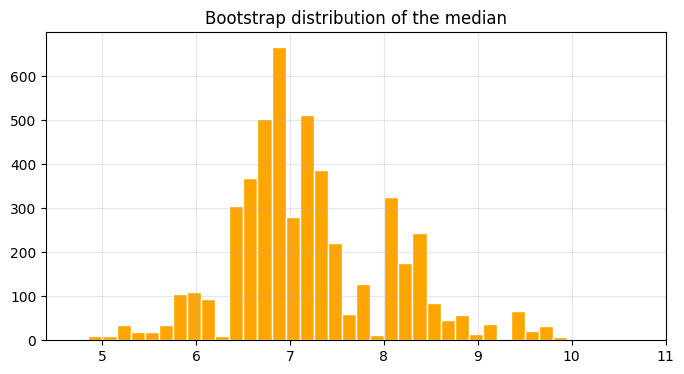

In [38]:
sample = rng.choice(population, size=200)

boot_medians = np.array([
    np.median(rng.choice(sample, size=len(sample), replace=True))
    for _ in range(5000)
])

print(f"Sample median:             {np.median(sample):.2f}")
print(f"Bootstrap SE of median:    {boot_medians.std():.2f}")
print(f"95% bootstrap interval:    {np.percentile(boot_medians, [2.5, 97.5]).round(2)}")
print(f"True population median:    {np.median(population):.2f}")

plt.hist(boot_medians, bins=40, color="orange", edgecolor="white")
plt.title("Bootstrap distribution of the median"); plt.show()

---
## Part 2: Machine Learning and Statistical Inference

> **Big idea.** Fitting a model = **estimation**. Asking *"how much can I trust this coefficient?"* = **inference**.

We simulate house prices where we **choose the truth**: every extra square foot adds **\$0.15k (= \$150)**, and the base price is **\$50k**. Can regression recover that from noisy data?

     sqft  price_k
0  2798.0    443.6
1  1153.0    137.0
2   690.0    147.0
3  1932.0    297.3
4  1490.0    252.4


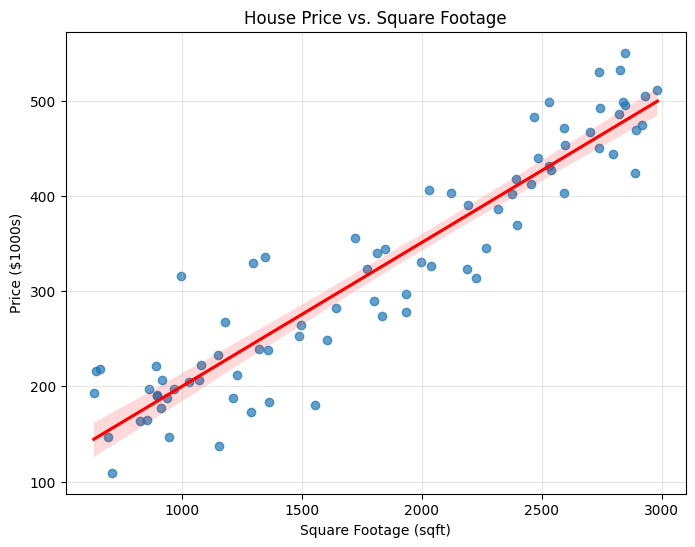

In [49]:
n = 80
sqft = rng.uniform(600, 3000, size=n)
true_intercept, true_slope = 50, 0.15                    # price in $1000s
price = true_intercept + true_slope * sqft + rng.normal(0, 40, size=n)   # noise

houses = pd.DataFrame({"sqft": sqft.round(), "price_k": price.round(1)})
print(houses.head())

plt.figure(figsize=(8,6))
sns.regplot(data=houses, x="sqft", y="price_k", scatter_kws={"alpha":0.7}, line_kws={"color":"red"})

plt.title("House Price vs. Square Footage")
plt.xlabel("Square Footage (sqft)")
plt.ylabel("Price ($1000s)")
plt.show()


Estimated slope:   0.1512   (true = 0.15)
Standard error:    0.0064
95% CI for slope:  (0.1384, 0.1640)
p-value:           3.32e-37   (H0: slope = 0)


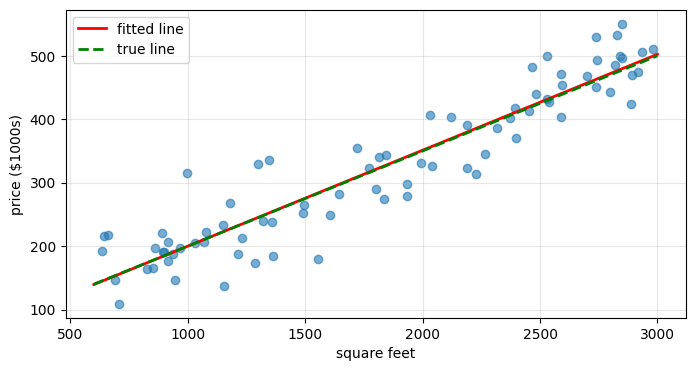

In [51]:
res = stats.linregress(houses["sqft"], houses["price_k"])      # ESTIMATION: fit the line

# INFERENCE: 95% confidence interval for the slope
t_crit = stats.t.ppf(0.975, df=n - 2)
ci_low, ci_high = res.slope - t_crit * res.stderr, res.slope + t_crit * res.stderr

print(f"Estimated slope:   {res.slope:.4f}   (true = {true_slope})")
print(f"Standard error:    {res.stderr:.4f}")
print(f"95% CI for slope:  ({ci_low:.4f}, {ci_high:.4f})")
print(f"p-value:           {res.pvalue:.2e}   (H0: slope = 0)")

plt.scatter(houses["sqft"], houses["price_k"], alpha=0.6)
xs = np.linspace(600, 3000, 100)
plt.plot(xs, res.intercept + res.slope * xs, "r", lw=2, label="fitted line")
plt.plot(xs, true_intercept + true_slope * xs, "g--", lw=2, label="true line")
plt.xlabel("square feet"); plt.ylabel("price ($1000s)"); plt.legend(); plt.show()

> **What to notice**
> - The fitted line (estimation) is close to, but not exactly on, the true line.
> - The CI (inference) gives a range of plausible slopes and it should contain 0.15.
> - A tiny p-value says: *"a slope this large would be very surprising if the real slope were 0."*

### 2.1 Is the 95% really 95%? Repeat the study 1,000 times

In [11]:
covered = 0
for _ in range(1000):
    x = rng.uniform(600, 3000, size=n)
    y = true_intercept + true_slope * x + rng.normal(0, 40, size=n)
    r = stats.linregress(x, y)
    lo, hi = r.slope - t_crit * r.stderr, r.slope + t_crit * r.stderr
    covered += (lo <= true_slope <= hi)

print(f"The CI contained the true slope in {covered/10:.1f}% of 1000 repeated studies")

The CI contained the true slope in 94.1% of 1000 repeated studies


> **What to notice:** this is *exactly* the frequentist meaning of "95% confidence". It describes the **procedure** over many repetitions, not one particular interval.

---
## Part 3: Parametric vs Non-Parametric

> **Big idea.** Parametric = *"I assume a shape, the data only fills in a few numbers."* Non-parametric = *"let the data draw the shape."*

### 3.1 When the assumption is right: both approaches agree

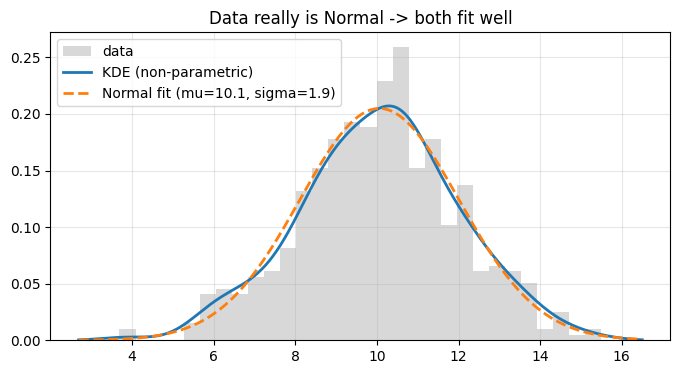

In [12]:
normal_data = rng.normal(loc=10, scale=2, size=500)
xs = np.linspace(normal_data.min() - 1, normal_data.max() + 1, 300)

mu_hat, sigma_hat = stats.norm.fit(normal_data)          # parametric: 2 numbers
kde = stats.gaussian_kde(normal_data)                     # non-parametric: shape from data

plt.hist(normal_data, bins=30, density=True, alpha=0.3, color="gray", label="data")
plt.plot(xs, kde(xs), lw=2, label="KDE (non-parametric)")
plt.plot(xs, stats.norm.pdf(xs, mu_hat, sigma_hat), "--", lw=2, label=f"Normal fit (mu={mu_hat:.1f}, sigma={sigma_hat:.1f})")
plt.legend(); plt.title("Data really is Normal -> both fit well"); plt.show()

### 3.2 When the assumption is wrong: the parametric model misleads

Imagine heights of a mix of two groups (e.g., two different species, or two sensor types). The data has **two peaks**, but a Normal can only describe **one**.

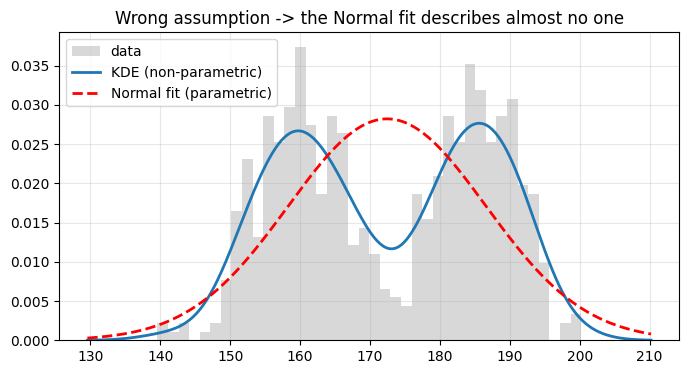

Normal says the typical value is 172, but how many data points are within 3 of that? 29 out of 600


In [13]:
bimodal = np.concatenate([rng.normal(160, 6, 300), rng.normal(185, 6, 300)])
xs = np.linspace(bimodal.min() - 10, bimodal.max() + 10, 400)

mu_b, sigma_b = stats.norm.fit(bimodal)
kde_b = stats.gaussian_kde(bimodal)

plt.hist(bimodal, bins=40, density=True, alpha=0.3, color="gray", label="data")
plt.plot(xs, kde_b(xs), lw=2, label="KDE (non-parametric)")
plt.plot(xs, stats.norm.pdf(xs, mu_b, sigma_b), "--", lw=2, color="red", label="Normal fit (parametric)")
plt.legend(); plt.title("Wrong assumption -> the Normal fit describes almost no one"); plt.show()

print(f"Normal says the typical value is {mu_b:.0f}, but how many data points are within 3 of that?",
      int(np.sum(np.abs(bimodal - mu_b) < 3)), "out of", len(bimodal))

> **What to notice**
> - **Parametric**: compact (2 numbers), efficient with little data, but **wrong if the assumed shape is wrong**.
> - **Non-parametric**: flexible, but needs more data and gives no tidy summary.
> - Trade-off: *bias from wrong assumptions* vs *variance from flexibility*. You will meet this again in model evaluation.

### 3.3 Real data: California housing

We use median **income** per district (in \$10k units). Real data is rarely perfectly Normal. Which parametric family fits better?

Loaded California housing: (20640, 9)


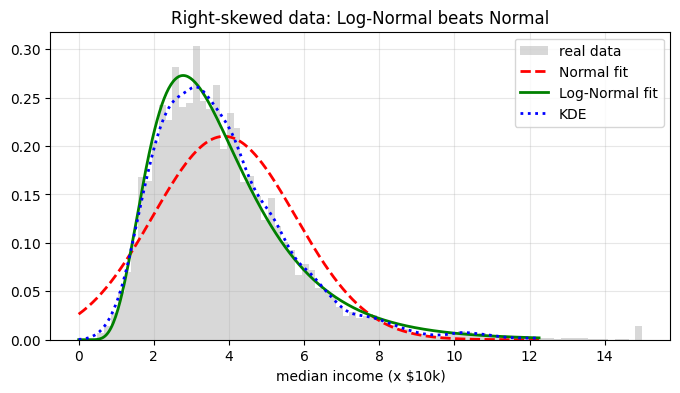

In [14]:
try:
    from sklearn.datasets import fetch_california_housing
    cal = fetch_california_housing(as_frame=True).frame
    income = cal["MedInc"].values
    print("Loaded California housing:", cal.shape)
except Exception as e:                     # offline fallback so the notebook still runs
    print("Could not download dataset, using simulated stand-in:", type(e).__name__)
    income = rng.lognormal(mean=1.2, sigma=0.5, size=20000)

xs = np.linspace(0, np.percentile(income, 99.5), 400)

mu_i, sd_i = stats.norm.fit(income)
s_i, loc_i, scale_i = stats.lognorm.fit(income, floc=0)

plt.hist(income, bins=80, density=True, alpha=0.3, color="gray", label="real data")
plt.plot(xs, stats.norm.pdf(xs, mu_i, sd_i), "r--", lw=2, label="Normal fit")
plt.plot(xs, stats.lognorm.pdf(xs, s_i, loc_i, scale_i), "g-", lw=2, label="Log-Normal fit")
plt.plot(xs, stats.gaussian_kde(income)(xs), "b:", lw=2, label="KDE")
plt.legend(); plt.xlabel("median income (x $10k)"); plt.title("Right-skewed data: Log-Normal beats Normal"); plt.show()

> **What to notice:** the Normal predicts negative incomes and misses the long right tail. The Log-Normal is also parametric (just 2 numbers) but has a **better-suited shape**. Choosing the right family matters.

---
## Part 4: Maximum Likelihood Estimation (MLE)

> **Big idea.** Try many candidate parameter values. For each, ask: *"how probable would my observed data be if this were the truth?"* Pick the winner.

### 4.1 Likelihood by hand, step by step

Take just **3 data points** and test one candidate: μ = 5, σ = 1.5.

In [15]:
tiny = np.array([4.2, 5.1, 6.3])

dens = stats.norm.pdf(tiny, loc=5, scale=1.5)       # f(x_i | theta) for each point
print("Density of each point:", dens.round(4))
print("Likelihood  L = product:   ", dens.prod())
print("Log-likelihood = sum of logs:", np.log(dens).sum())

Density of each point: [0.2307 0.2654 0.1827]
Likelihood  L = product:    0.011184672956517032
Log-likelihood = sum of logs: -4.493210923938511


Multiplying many small numbers gets tiny very fast (numerical underflow), so we **add logs instead**. The best μ is the same either way.

### 4.2 Scan over candidate values of μ

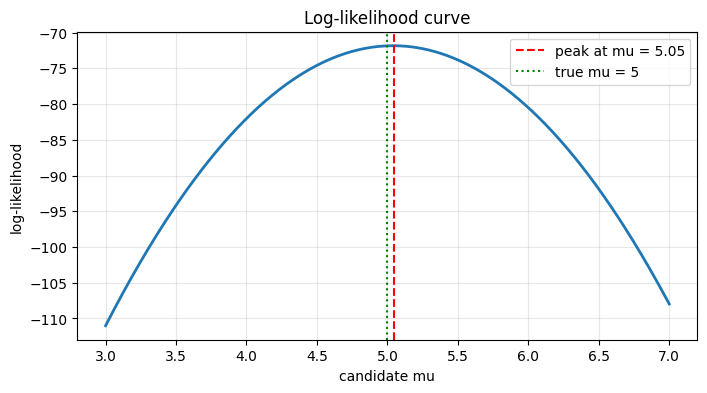

Peak of curve: 5.045   |   sample mean: 5.040


In [16]:
sample = rng.normal(loc=5, scale=1.5, size=40)

mu_grid = np.linspace(3, 7, 400)
sigma_fixed = sample.std()                          # keep sigma fixed to see mu clearly

loglik = [stats.norm.logpdf(sample, loc=m, scale=sigma_fixed).sum() for m in mu_grid]
best_mu = mu_grid[np.argmax(loglik)]

plt.plot(mu_grid, loglik, lw=2)
plt.axvline(best_mu, color="red", ls="--", label=f"peak at mu = {best_mu:.2f}")
plt.axvline(5, color="green", ls=":", label="true mu = 5")
plt.xlabel("candidate mu"); plt.ylabel("log-likelihood"); plt.legend()
plt.title("Log-likelihood curve"); plt.show()

print(f"Peak of curve: {best_mu:.3f}   |   sample mean: {sample.mean():.3f}")

> **What to notice:** the peak sits **exactly on the sample mean**. For a Normal, the MLE of μ *is* the sample mean, which is why the average feels so natural.

### 4.3 Let the computer search (this is how ML models are trained!)

Real models have many parameters, so we can't scan a grid. We use an **optimizer** to minimize the *negative* log-likelihood. This is the same idea behind training logistic regression and neural networks.

In [17]:
def neg_loglik(params):
    mu, log_sigma = params                      # optimize log(sigma) so sigma stays positive
    return -stats.norm.logpdf(sample, loc=mu, scale=np.exp(log_sigma)).sum()

result = optimize.minimize(neg_loglik, x0=[0.0, 0.0])
mu_opt, sigma_opt = result.x[0], np.exp(result.x[1])

mu_fit, sigma_fit = stats.norm.fit(sample)

print(f"Our optimizer:   mu={mu_opt:.4f}, sigma={sigma_opt:.4f}")
print(f"scipy norm.fit:  mu={mu_fit:.4f}, sigma={sigma_fit:.4f}")
print(f"Sample mean / std (ddof=0): {sample.mean():.4f} / {sample.std(ddof=0):.4f}")
print(f"Sample std with ddof=1:     {sample.std(ddof=1):.4f}  <- slightly larger")

Our optimizer:   mu=5.0404, sigma=1.4577
scipy norm.fit:  mu=5.0404, sigma=1.4577
Sample mean / std (ddof=0): 5.0404 / 1.4577
Sample std with ddof=1:     1.4763  <- slightly larger


> **What to notice**
> - Our hand-made optimizer and `scipy` agree.
> - The MLE of σ uses `ddof=0` (divide by *n*), which is slightly **biased low**. The `ddof=1` version corrects that. MLE is great but not always unbiased.

### 4.4 More data → a sharper peak (more certainty)

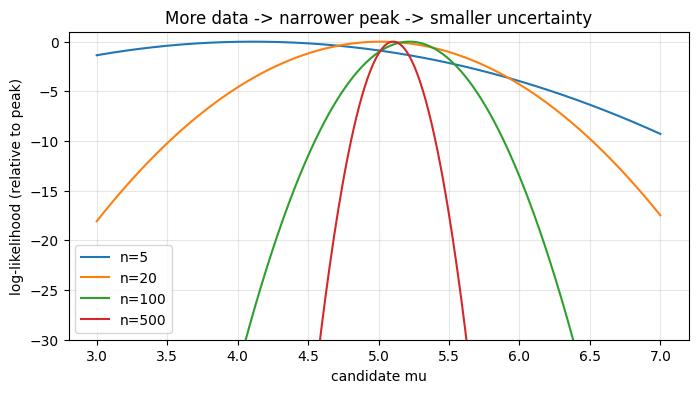

In [18]:
for n_obs in [5, 20, 100, 500]:
    s = rng.normal(5, 1.5, size=n_obs)
    ll = np.array([stats.norm.logpdf(s, m, 1.5).sum() for m in mu_grid])
    plt.plot(mu_grid, ll - ll.max(), label=f"n={n_obs}")       # shift so peaks align at 0
plt.ylim(-30, 1); plt.xlabel("candidate mu"); plt.ylabel("log-likelihood (relative to peak)")
plt.legend(); plt.title("More data -> narrower peak -> smaller uncertainty"); plt.show()

> **What to notice:** with few points, many μ values are almost equally good (flat top). With many points, the peak is sharp. This is the link between MLE and **inference**: the *curvature* of the log-likelihood determines the standard error.

---
## Part 5: Common Distributions

> **Big idea.** Each distribution is a *story* about how data gets generated. Pick the story that matches your data.

### 5.1 The gallery

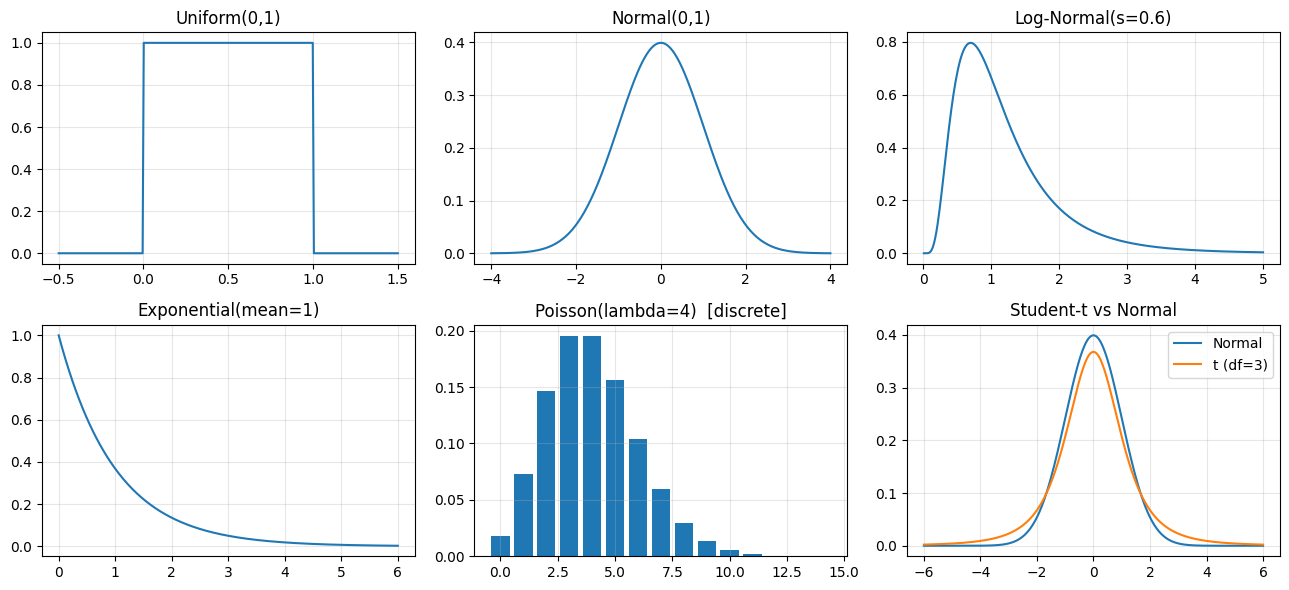

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))

x = np.linspace(-0.5, 1.5, 300)
axes[0,0].plot(x, stats.uniform(0, 1).pdf(x)); axes[0,0].set_title("Uniform(0,1)")

x = np.linspace(-4, 4, 300)
axes[0,1].plot(x, stats.norm(0, 1).pdf(x)); axes[0,1].set_title("Normal(0,1)")

x = np.linspace(0.01, 5, 300)
axes[0,2].plot(x, stats.lognorm(s=0.6).pdf(x)); axes[0,2].set_title("Log-Normal(s=0.6)")

x = np.linspace(0, 6, 300)
axes[1,0].plot(x, stats.expon(scale=1).pdf(x)); axes[1,0].set_title("Exponential(mean=1)")

k = np.arange(0, 15)
axes[1,1].bar(k, stats.poisson(mu=4).pmf(k)); axes[1,1].set_title("Poisson(lambda=4)  [discrete]")

x = np.linspace(-6, 6, 300)
axes[1,2].plot(x, stats.norm.pdf(x), label="Normal")
axes[1,2].plot(x, stats.t(df=3).pdf(x), label="t (df=3)"); axes[1,2].legend()
axes[1,2].set_title("Student-t vs Normal")

plt.tight_layout(); plt.show()

### 5.2 Poisson and Exponential are two views of the same process

Customers arrive randomly at **4 per hour** on average.
- **Poisson** counts *how many* arrive in an hour.
- **Exponential** measures *how long you wait* between arrivals.

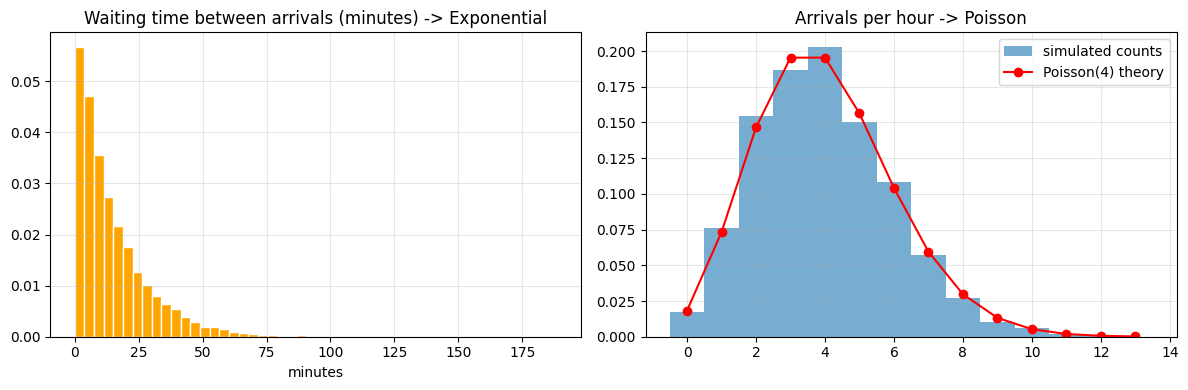

Average gap: 15.1 min  (theory: 15 min)
Average count per hour: 3.96  (theory: 4)


In [20]:
rate = 4                                           # arrivals per hour
gaps = rng.exponential(scale=1/rate, size=20000)    # waiting times in hours
arrival_times = np.cumsum(gaps)

hours = int(arrival_times[-1])
counts = np.histogram(arrival_times, bins=np.arange(0, hours + 1))[0]   # arrivals per hour

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(gaps * 60, bins=50, density=True, color="orange", edgecolor="white")
ax[0].set_title("Waiting time between arrivals (minutes) -> Exponential"); ax[0].set_xlabel("minutes")

k = np.arange(0, 14)
ax[1].hist(counts, bins=np.arange(-0.5, 14.5), density=True, alpha=0.6, label="simulated counts")
ax[1].plot(k, stats.poisson(rate).pmf(k), "ro-", label="Poisson(4) theory")
ax[1].set_title("Arrivals per hour -> Poisson"); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"Average gap: {gaps.mean()*60:.1f} min  (theory: {60/rate:.0f} min)")
print(f"Average count per hour: {counts.mean():.2f}  (theory: {rate})")

### 5.3 Why the Normal is everywhere: the Central Limit Theorem

Take a **very non-Normal** distribution (Exponential, heavily skewed). Average many draws, and the *averages* become bell-shaped.

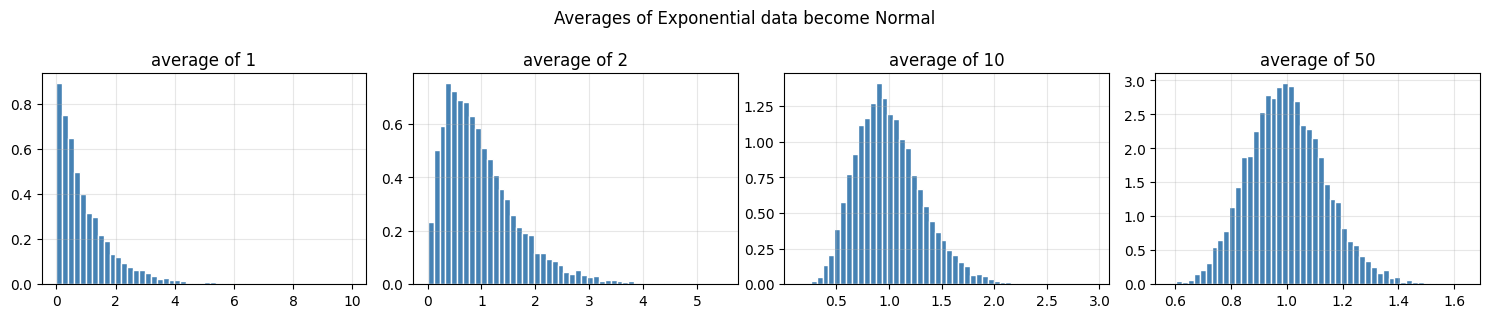

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=False)
for ax, n_avg in zip(axes, [1, 2, 10, 50]):
    avgs = rng.exponential(1, size=(10000, n_avg)).mean(axis=1)
    ax.hist(avgs, bins=50, density=True, color="steelblue", edgecolor="white")
    ax.set_title(f"average of {n_avg}")
plt.suptitle("Averages of Exponential data become Normal"); plt.tight_layout(); plt.show()

### 5.4 Student-t: why heavier tails matter

How surprising is a value more than 3 standard units from the center?

In [22]:
print("P(|X| > 3):")
print(f"  Normal:       {2 * stats.norm.sf(3):.4f}")
print(f"  t (df=10):    {2 * stats.t.sf(3, df=10):.4f}")
print(f"  t (df=3):     {2 * stats.t.sf(3, df=3):.4f}")

P(|X| > 3):
  Normal:       0.0027
  t (df=10):    0.0133
  t (df=3):     0.0577


> **What to notice:** with small samples, extreme values are **more likely** than a Normal suggests (that is why we used `stats.t.ppf` for the regression CI in Part 2). As df grows, the t becomes the Normal.

### 5.5 Quick "which distribution?" guide

| Your data looks like... | Try |
|---|---|
| Any value in a range, equally likely | Uniform |
| Symmetric bell, sums/averages of many small effects | Normal |
| Positive, right-skewed, multiplicative effects (income, prices) | Log-Normal |
| Waiting time until the next event | Exponential |
| Count of events per interval | Poisson |
| Small sample, unknown variance | Student-t |

---
## Part 6: Frequentist vs Bayesian

> **Big idea.** Same data, same math, different *interpretation*.
> - **Frequentist:** the parameter is a fixed unknown number. Probability = long-run frequency of a *procedure*.
> - **Bayesian:** the parameter is uncertain, described by a *distribution* that we update as data arrives.

### 6.1 The coin example: 14 heads in 20 flips

In [23]:
n_flips, n_heads = 20, 14
p_hat = n_heads / n_flips

# --- Frequentist ---
se = np.sqrt(p_hat * (1 - p_hat) / n_flips)
ci = (p_hat - 1.96 * se, p_hat + 1.96 * se)
print(f"Frequentist: p_hat = {p_hat:.2f}, 95% CI = ({ci[0]:.4f}, {ci[1]:.4f})")

# --- Bayesian: Beta(2,2) prior + Binomial data -> Beta posterior ---
prior_a, prior_b = 2, 2
post_a, post_b = prior_a + n_heads, prior_b + (n_flips - n_heads)
posterior = stats.beta(post_a, post_b)
print(f"Bayesian:    posterior mean = {posterior.mean():.2f}, "
      f"95% credible interval = ({posterior.ppf(0.025):.3f}, {posterior.ppf(0.975):.3f})")
print(f"P(coin is biased toward heads, p > 0.5 | data) = {posterior.sf(0.5):.3f}")

Frequentist: p_hat = 0.70, 95% CI = (0.4992, 0.9008)
Bayesian:    posterior mean = 0.67, 95% credible interval = (0.471, 0.836)
P(coin is biased toward heads, p > 0.5 | data) = 0.953


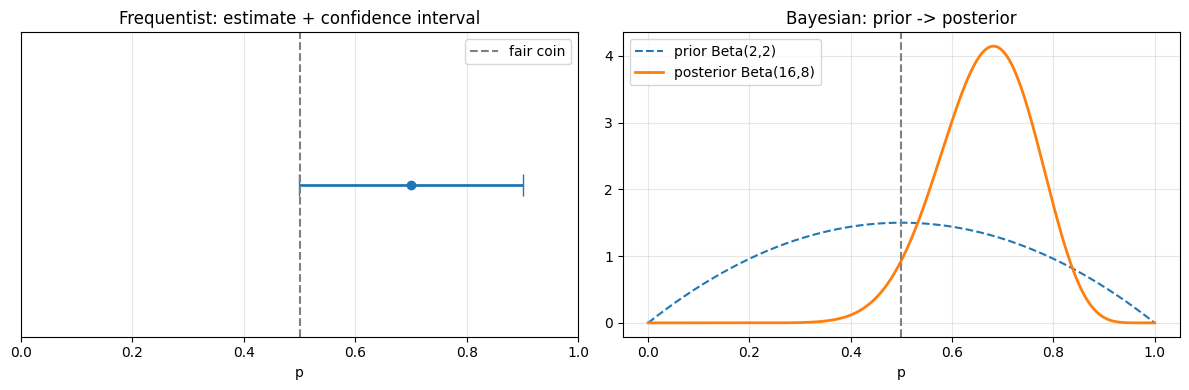

In [24]:
p = np.linspace(0, 1, 500)
prior = stats.beta(prior_a, prior_b)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Frequentist picture
ax[0].errorbar(p_hat, 0, xerr=1.96 * se, fmt="o", capsize=8, lw=2, color="C0")
ax[0].axvline(0.5, color="gray", ls="--", label="fair coin")
ax[0].set_xlim(0, 1); ax[0].set_yticks([]); ax[0].legend()
ax[0].set_title("Frequentist: estimate + confidence interval"); ax[0].set_xlabel("p")

# Bayesian picture
ax[1].plot(p, prior.pdf(p), "--", label="prior Beta(2,2)")
ax[1].plot(p, posterior.pdf(p), lw=2, label=f"posterior Beta({post_a},{post_b})")
ax[1].axvline(0.5, color="gray", ls="--")
ax[1].set_title("Bayesian: prior -> posterior"); ax[1].set_xlabel("p"); ax[1].legend()
plt.tight_layout(); plt.show()

> **What to notice**
> - The frequentist answer is **one number + an interval** about the *procedure*.
> - The Bayesian answer is a **whole distribution**, so we can directly ask *"how likely is p > 0.5?"*
> - The posterior mean (0.67) is pulled slightly toward the prior's center (0.5), which is **shrinkage**.

### 6.2 How much does the prior matter?

Same data (14/20), three different prior beliefs: *no opinion*, *mild*, and *strong "it's fair"*.

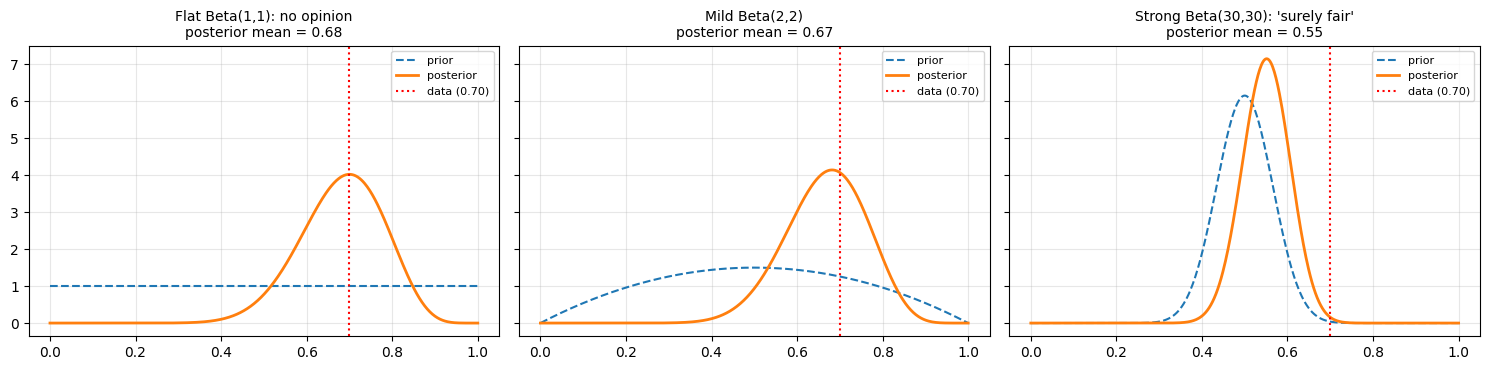

In [25]:
priors = {"Flat Beta(1,1): no opinion": (1, 1),
          "Mild Beta(2,2)": (2, 2),
          "Strong Beta(30,30): 'surely fair'": (30, 30)}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (name, (a, b)) in zip(axes, priors.items()):
    post = stats.beta(a + n_heads, b + n_flips - n_heads)
    ax.plot(p, stats.beta(a, b).pdf(p), "--", label="prior")
    ax.plot(p, post.pdf(p), lw=2, label="posterior")
    ax.axvline(p_hat, color="red", ls=":", label="data (0.70)")
    ax.set_title(f"{name}\nposterior mean = {post.mean():.2f}", fontsize=10)
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 6.3 ...and does the prior still matter with more data?

Now **10x the data** at the same ratio: 140 heads in 200 flips.

In [26]:
big_n, big_heads = 200, 140
print(f"{'Prior':<38}{'20 flips':>10}{'200 flips':>12}")
for name, (a, b) in priors.items():
    m_small = (a + n_heads) / (a + b + n_flips)
    m_big = (a + big_heads) / (a + b + big_n)
    print(f"{name:<38}{m_small:>10.3f}{m_big:>12.3f}")
print("\nFrequentist p_hat:", 14/20, "->", 140/200)

Prior                                   20 flips   200 flips
Flat Beta(1,1): no opinion                 0.682       0.698
Mild Beta(2,2)                             0.667       0.696
Strong Beta(30,30): 'surely fair'          0.550       0.654

Frequentist p_hat: 0.7 -> 0.7


> **What to notice:** with little data the prior has a visible effect; with lots of data the **data overwhelms the prior** and everyone converges to roughly the same answer.

### 6.4 Watching Bayesian learning happen, flip by flip

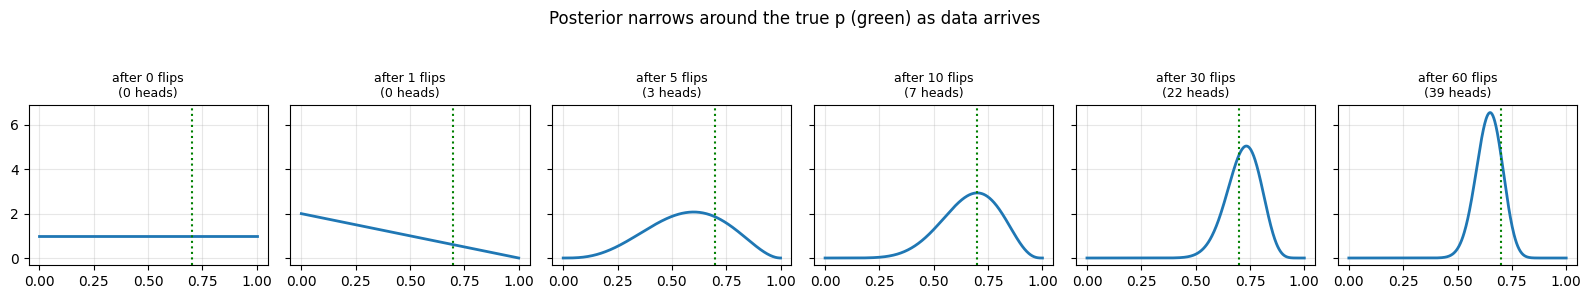

In [27]:
true_p = 0.7
flips = rng.random(60) < true_p                    # simulated coin: True = heads

a, b = 1, 1                                         # start with a flat prior
checkpoints = [0, 1, 5, 10, 30, 60]
fig, axes = plt.subplots(1, len(checkpoints), figsize=(16, 2.8), sharey=True)

for ax, k in zip(axes, checkpoints):
    heads = flips[:k].sum()
    post = stats.beta(a + heads, b + k - heads)
    ax.plot(p, post.pdf(p), lw=2)
    ax.axvline(true_p, color="green", ls=":")
    ax.set_title(f"after {k} flips\n({heads} heads)", fontsize=9)
plt.suptitle("Posterior narrows around the true p (green) as data arrives", y=1.05)
plt.tight_layout(); plt.show()

### 6.5 Checking the frequentist CI on a small sample

Is the "95%" interval from the README really 95% when n = 20? Repeat the coin experiment 10,000 times with a known true p = 0.9 (a coin that lands heads 90% of the time).

In [28]:
true_p, n_flips, reps = 0.9, 20, 10000

heads = rng.binomial(n_flips, true_p, size=reps)
p_hats = heads / n_flips
ses = np.sqrt(p_hats * (1 - p_hats) / n_flips)

lo, hi = p_hats - 1.96 * ses, p_hats + 1.96 * ses
print(f"Simple (Wald) 95% CI covers the true p in {np.mean((lo <= true_p) & (true_p <= hi))*100:.1f}% of experiments")

# Bayesian credible interval with a flat prior, checked the same way
post_lo = stats.beta.ppf(0.025, 1 + heads, 1 + n_flips - heads)
post_hi = stats.beta.ppf(0.975, 1 + heads, 1 + n_flips - heads)
print(f"Bayesian 95% credible interval covers true p in {np.mean((post_lo <= true_p) & (true_p <= post_hi))*100:.1f}%")

Simple (Wald) 95% CI covers the true p in 87.0% of experiments
Bayesian 95% credible interval covers true p in 95.6%


> **What to notice:** the simple formula falls clearly **short of 95%** with small samples when p is far from 0.5. It is an *approximation* that improves as n grows (try `n_flips = 200`). Statisticians have better small-sample intervals (e.g., Wilson), but the key lesson is that frequentist guarantees are about **long-run behavior, and we can test them by simulation**. The Bayesian interval answers a different question, so its coverage need not be exactly 95%.

---
## Recap

- **Estimation** computes a value; **inference** attaches uncertainty (SE, CI, p-value, bootstrap). *Parts 1-2*
- **Parametric** models assume a shape with few parameters; **non-parametric** let data draw the shape. Wrong assumptions hurt. *Part 3*
- **MLE** picks the parameters that make the observed data most probable; optimizers do this when there is no formula. *Part 4*
- Each **distribution** tells a data-generating story: Normal (sums), Log-Normal (multiplicative), Exponential (waiting), Poisson (counts), t (small samples). *Part 5*
- **Frequentist**: fixed parameter, guarantees about procedures. **Bayesian**: parameter has a distribution updated by data; priors matter less as data grows. *Part 6*

## Try it yourself

1. In Part 1.2, change the population to `rng.normal(50, 10, 100_000)`. Does the SE still match?
2. In Part 1.4, bootstrap the **mean** instead of the median and compare to the `s/√n` formula.
3. In Part 2, increase the noise from `40` to `150`. What happens to the CI width and p-value?
4. In Part 3.3, compute `stats.kstest(income, "norm", args=(mu_i, sd_i))` vs the Log-Normal. Which fits better?
5. In Part 4.3, fit an **Exponential** by MLE and confirm the answer equals `1 / sample mean`.
6. In Part 6, pick your own prior and data (e.g., 3 heads in 3 flips with a strong "fair" prior). Who wins?

------------------------------------------

| <img src="https://github.com/madhawapolkotuwa.png" width="80" style="border-radius: 50%;"> | **MPCoding**<br>*Machine Learning Tutorial Series*<br><br> [![YouTube](https://img.shields.io/badge/YouTube-%23FF0000.svg?style=for-the-badge&logo=YouTube&logoColor=white)](https://www.youtube.com/@MP-Coding) [![GitHub](https://img.shields.io/badge/github-repo-blue?logo=github)](https://github.com/madhawapolkotuwa) |
|---|---|

<p align="left" style="font-size: 0.85em; color: gray; margin-top: 10px;">
  © 2026 MPCoding. Educational materials are free to use with proper attribution.
</p>